In [61]:
# # PROJET
# A rendre le 15 décembre (groupe de 3 maximum)
# Ce projet se concentre non seulement sur les aspects techniques, mais aussi sur l'application métier
# et le choix stratégique du meilleur modèle de machine learning selon des métriques pertinentes.
# Contexte du Projet : Optimisation d'une Campagne Marketing Bancaire
# Dans un contexte de plus en plus concurrentiel, les institutions financières cherchent à maximiser
# l'efficacité de leurs campagnes de marketing tout en optimisant l'expérience client. La campagne de
# marketing direct de notre projet cible la promotion de dépôts à terme auprès des clients existants.
# Pour réduire les coûts et améliorer le taux de conversion, l'institution souhaite identifier les clients
# les plus susceptibles de souscrire à cette offre.
# Objectif du Projet :
# Le but est de prédire si un client acceptera ("yes") ou refusera ("no") l'offre de dépôt à terme, en
# s'appuyant sur les données issues des interactions précédentes et les caractéristiques
# socioéconomiques. En tant que data scientists, vous devrez explorer, préparer et modéliser les
# données afin de fournir un outil de prédiction précis et interprétable.
# Étapes Détaillées du Projet :
# 1. Exploration des Données et Contexte Métier
# Description des données :
# Les données comprennent les informations démographiques des clients, leurs interactions passées
# avec la banque, et les résultats de campagnes marketing antérieures. Vous les trouverez sur le site
# https://archive.ics.uci.edu/dataset/222/bank+marketing
# Files
# bank.zip 565.5 KB
# bank-additional.zip
# Problématique métier :
# La souscription à un dépôt à terme est une décision importante pour un client. La banque souhaite
# minimiser les coûts liés à des campagnes marketing inefficaces et maximiser le retour sur
# investissement (ROI).
# Métrique métier clé :
# En plus des métriques standards comme l'accuracy ou le F1score, la précision et le recall sont
# essentielles. En effet, un faux positif (prédire que le client acceptera alors qu'il refuse) entraîne des
# coûts de marketing inutiles, tandis qu'un faux négatif (manquer un client prêt à souscrire) représente
# une opportunité perdue.
# 2. Préparation des Données
# Nettoyage et transformation :
# Traitement des valeurs manquantes, normalisation des données numériques.
# Encodage des variables catégorielles (par exemple : OneHot Encoding).
# Analyse exploratoire :
# Visualisation des distributions de variables clés (âge, profession, éducation, etc.) et exploration de
# leur influence sur la souscription (variable cible `y`).
# Stratégies de mise à l'échelle :
# Normalisation des valeurs numériques pour une meilleure convergence des modèles.
# 3. Création et Entraînement de Modèles
# Modèles proposés :
# Un simple Knn
# Régression Logistique : Modèle de base interprétable pour les prédictions binaires.
# Arbres de Décision : Modèle intuitif, utile pour l'interprétabilité.
# Random Forest : Ensemble d'arbres de décision offrant souvent de meilleures performances globales.
# Gradient Boosting (XGBoost) : Modèle puissant pour les prédictions, avec une capacité élevée à gérer
# les données déséquilibrées.
# Méthodes avancées (optionnel)
# 4. Évaluation des Modèles :
# Métriques de performance clés :
# Accuracy : Pourcentage de prédictions correctes. Utile mais peut être trompeur si les classes sont
# déséquilibrées.
# Précision (Precision) : Proportion de prédictions positives correctes par rapport à l'ensemble des
# prédictions positives. Réduit les faux positifs (évite les coûts inutiles).
# Rappel (Recall ou Sensibilité) : Proportion de vraies positives détectées parmi toutes les vraies
# positives possibles. Réduit les faux négatifs (maximise les opportunités).
# F1score : Moyenne harmonique de la précision et du rappel. Idéal pour évaluer l'équilibre entre ces
# deux métriques.
# Courbe ROC AUC : Indicateur de la performance globale du modèle.
# Choix du modèle le plus adapté :
# Si la banque souhaite maximiser les souscriptions positives (minimiser les faux négatifs), le rappel
# sera privilégié.
# Si la banque cherche à réduire les coûts liés à des campagnes inutiles (minimiser les faux positifs), la
# précision sera le critère principal.
# Un F1score élevé peut représenter un bon compromis lorsque les enjeux de précision et de rappel
# sont équilibrés.
# 5. Optimisation du Modèle :
# Tuning des hyperparamètres à l'aide de la recherche en grille ou en random search pour obtenir la
# meilleure performance.
# Analyse des variables importantes pour comprendre les facteurs influençant la souscription.
# 6. Interprétation et Application Métier
# Présentation des résultats au travers de visualisations claires (ex : importance des variables, courbe
# ROC, matrice de confusion).
# Cas métier : Par exemple, identifier des segments de clients à cibler en priorité lors des prochaines
# campagnes.
# 7. Mise en Production (optionnel)
# Intégration du modèle avec un tableau de bord (par exemple, via Streamlit) pour permettre aux
# utilisateurs métiers de tester différents scénarios et visualiser les prévisions.
# Outils Utilisés :
# Langage de programmation : Python
# Bibliothèques : Pandas, NumPy, Scikitlearn, XGBoost, Matplotlib, Seaborn
# Visualisation et tableau de bord : Streamlit (optionnel)
# Résumé du Projet :
# Vous travailleraient non seulement sur la préparation, l'entraînement, et l'optimisation d'un modèle
# de machine learning, mais aussi considérer le métrique métier les plus pertinentes pour prendre des
# décisions éclairées, tout en gardant à l'esprit les implications économiques de leurs prédictions. Ce
# projet permet de mettre en pratique l'optimisation des campagnes marketing, une compétence clé
# pour tout data scientist dans le secteur financier ou du marketing.

In [62]:
import pandas as pd

BANK FULL CSV

In [63]:
# Data exploration
data_full = pd.read_csv('./data/bank-full.csv', delimiter=';')
data_full.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [64]:
data_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [65]:
data_full.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [66]:
# # SHPW CORRELATION BETWEEN VARIABLES
# import seaborn as sns

# sns.heatmap(data_full.corr(), annot=True)

In [67]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split


print(data_full.isnull().sum())


data_encoded = pd.get_dummies(data_full, columns=['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome'])


X = data_encoded.drop('y', axis=1)
y = data_encoded['y'].apply(lambda x: 1 if x == 'yes' else 0)


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [68]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)


y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]


print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, y_pred_proba))


Accuracy: 0.9060011795930404
Precision: 0.6636271529888551
Recall: 0.40988735919899877
F1 Score: 0.5067698259187621
ROC AUC Score: 0.927290312748867


In [69]:
from sklearn.model_selection import GridSearchCV

# Paramètres à tester
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
}


grid_search = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=3, scoring='f1', verbose=2)
grid_search.fit(X_train, y_train)


print("Best parameters:", grid_search.best_params_)

best_model = grid_search.best_estimator_
y_pred_optimized = best_model.predict(X_test)
print("Optimized F1 Score:", f1_score(y_test, y_pred_optimized))


Fitting 3 folds for each of 36 candidates, totalling 108 fits
[CV] END max_depth=None, min_samples_split=2, n_estimators=50; total time=   1.0s
[CV] END max_depth=None, min_samples_split=2, n_estimators=50; total time=   0.9s
[CV] END max_depth=None, min_samples_split=2, n_estimators=50; total time=   1.0s
[CV] END max_depth=None, min_samples_split=2, n_estimators=100; total time=   2.0s
[CV] END max_depth=None, min_samples_split=2, n_estimators=100; total time=   2.0s
[CV] END max_depth=None, min_samples_split=2, n_estimators=100; total time=   1.9s
[CV] END max_depth=None, min_samples_split=2, n_estimators=200; total time=   4.2s
[CV] END max_depth=None, min_samples_split=2, n_estimators=200; total time=   4.3s
[CV] END max_depth=None, min_samples_split=2, n_estimators=200; total time=   4.2s
[CV] END max_depth=None, min_samples_split=5, n_estimators=50; total time=   0.9s
[CV] END max_depth=None, min_samples_split=5, n_estimators=50; total time=   0.9s
[CV] END max_depth=None, min_s

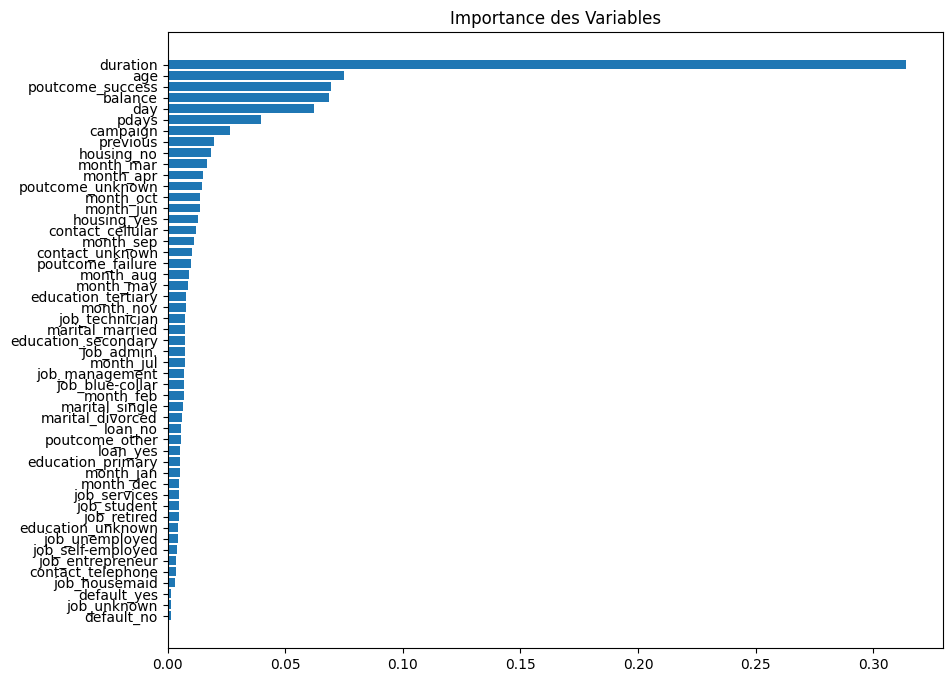

In [70]:
import matplotlib.pyplot as plt

importances = best_model.feature_importances_
feature_names = X.columns
sorted_indices = importances.argsort()

plt.figure(figsize=(10, 8))
plt.barh(range(len(sorted_indices)), importances[sorted_indices], align='center')
plt.yticks(range(len(sorted_indices)), [feature_names[i] for i in sorted_indices])
plt.title('Importance des Variables')
plt.show()


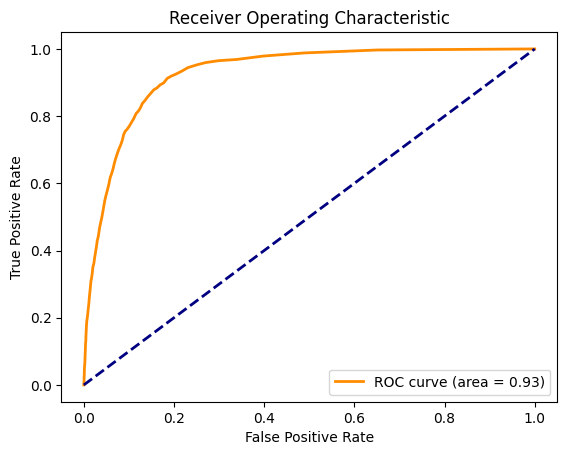

In [71]:
from sklearn.metrics import roc_curve, auc

# Calcul de la courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

# Visualisation
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

BANK CSV

In [72]:
data = pd.read_csv('./data/bank.csv', delimiter=';')
data.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [73]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB


In [74]:
data.describe()

,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


In [75]:
print(data.isnull().sum())

data_encoded = pd.get_dummies(data, columns=['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome'])

X = data_encoded.drop('y', axis=1)
y = data_encoded['y'].apply(lambda x: 1 if x == 'yes' else 0)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [76]:
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8968312453942521
Precision: 0.6111111111111112
Recall: 0.21710526315789475
F1 Score: 0.32038834951456313
